# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis, **Crest**
neural crest) were scored in 02 against the shared **union** control pool and graph-smoothed. Here
we render them as deliverables (raw per-cell scores) and evaluate **Gate 2**.

**Gate 2 (non-branching case).** Puram's branching manifold splits Gast and pSom into *distinct
arms* with mutual cross-repression and Crest terminal. A non-branching manifold instead shows a
**single developmental gradient** with an inverse terminal end. In Raghavan 2021 that gradient is
the **gastrulation/somitogenesis → neural-crest** axis: Gast and pSom **co-vary** in space
(smoothed r ≈ +0.32 — they overlap, they do *not* cross-repress) and both fall along pseudotime
(pSom rho ≈ −0.70, Gast ≈ −0.44), while Crest rises to a terminal end (rho ≈ +0.59; Crest-high
decile late in pseudotime) and is spatially anti-correlated with both (r ≈ −0.80 / −0.69). The
single-axis, inverse-terminal pattern **is present**, so **Gate 2 = GO**; with Gast/pSom overlapping
(no bifurcation) the cross-repression test is **Gate 3 = NA**.

**The branching temptation (Raghavan's classical/basal axis) does not qualify.** Raghavan is the
classical↔basal plasticity paper, so a bifurcation is plausible — but the classical/basal axis is
*orthogonal* to the embryonic modules (02: pSom vs classical/basal r ≈ +0.04/+0.05). The gates
concern the embryonic-developmental axis, and on that axis the geometry is a single gradient, not a
Gast/pSom hub. Deliverable: `signatures.h5ad`, `{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
ds   = name[:-2] if name.endswith('-4') else name
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed in 02)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 7168 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 73/81 genes present
pSom: 85/98 genes present
Crest: 103/104 genes present


### Gate 2 — module geography on the manifold
Quantitative test of the non-branching signature: (i) Gast/pSom co-vary and both anti-correlate
with Crest (single axis, not opposing arms); (ii) along pseudotime pSom & Gast decline and Crest
rises (Crest terminal); (iii) the joint pSom&Crest-high enrichment: a co-expression hub (Puram
signature) shows enrichment > 1, whereas a clean inverse gradient shows depletion (< 1).

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if late)')
pz = (adata.obs['pSom']-adata.obs['pSom'].mean())/adata.obs['pSom'].std()
cz = (adata.obs['Crest']-adata.obs['Crest'].mean())/adata.obs['Crest'].std()
joint = ((pz>0.5)&(cz>0.5)).mean(); exp = (pz>0.5).mean()*(cz>0.5).mean()
print(f'joint pSom&Crest-high enrichment = {joint/exp:.2f} (<1 = inverse gradient, not a hub)')
gz = (adata.obs['Gast']-adata.obs['Gast'].mean())/adata.obs['Gast'].std()
jgp = ((gz>0.5)&(pz>0.5)).mean(); egp = (gz>0.5).mean()*(pz>0.5).mean()
print(f'joint Gast&pSom-high enrichment = {jgp/egp:.2f} (>1 = co-expression/overlap, not cross-repression)')
print('Gate 2: single Gast/pSom -> Crest gradient (Gast/pSom overlap, Crest inverse terminal) -> GO (non-branching)')
print('Gate 3: no Gast/pSom bifurcation -> NA')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.32
  Crest_sm vs Gast_sm: r = -0.80
  Crest_sm vs pSom_sm: r = -0.69
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.439
  pSom_sm: rho = -0.698
  Crest_sm: rho = +0.594
Neural-crest-high decile mean pseudotime = 0.68 (terminal if late)
joint pSom&Crest-high enrichment = 0.23 (<1 = inverse gradient, not a hub)
joint Gast&pSom-high enrichment = 1.15 (>1 = co-expression/overlap, not cross-repression)
Gate 2: single Gast/pSom -> Crest gradient (Gast/pSom overlap, Crest inverse terminal) -> GO (non-branching)
Gate 3: no Gast/pSom bifurcation -> NA


### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right (`X_umap_lin`), `size=30`, plasma, **raw**
(not smoothed) score per cell so Seq-Well dropout is visible (smoothing aided the analysis; the
deliverable shows raw, per task §Gate-2). Colorbar ticks data-driven.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


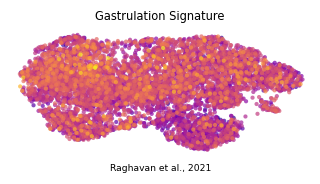

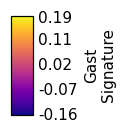

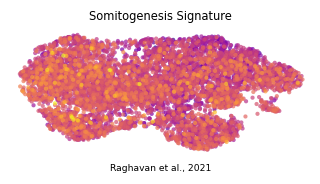

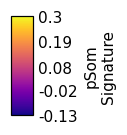

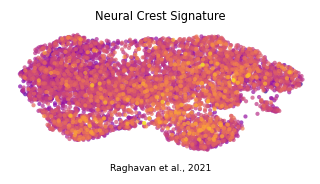

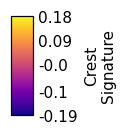

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_title(titles[m], size=7.5)
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Raghavan et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures data

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (7168, 16763)
